# 4. Development ablations: what we learned about inverting this drift generator

Notebooks 1–3 hold the test-set results. This notebook collects the **development experiments** that shaped the method,
or that show something interesting about this drift generator (`pixel_B_sota`) as a prior. Each section goes *math → code → results*.

**Scope: development only.** Development images, never test images; $n$ is stated in every heading
(1 to 8 images or classes). Tables show means and per-image values, without significance tests. One-image results
are illustrations, not evidence.

| Section | Question | Short answer | $n$ |
|---|---|---|---|
| 1 | What do the noise labels $z$ control, and what does $\varepsilon$? | $z$ sets the scene; $\varepsilon$ adjusts local detail | 8 classes |
| 2 | Can we feed the photo itself in place of $\varepsilon$? | No: the generator ignores it | 3 |
| 3 | CSGM pushes $\varepsilon$ off the Gaussian shell. Does keeping it Gaussian help? | No | 4 |
| 4 | Can we choose $z$ by measurement fit? | Yes, a small gain; LR loss predicts quality | 4 |
| 5 | Does averaging also rescue IADrift? | Yes: the averaging matters, not the adaptation | 6 |
| 6 | Can we suppress IADrift's high-frequency noise directly? | Yes, on one image | 1 |
| 7 | Also tried (one line each) | | |

**About the code cells.** They show each method in compact form. The code that produced the numbers is the runner named in the table below (`scripts/dev/`, built on the library
`iadrift/`); each has `--dry-run` and a `--smoke` check that reruns part of a saved run bit-exactly. The raw
development notebooks the runners were ported from are in `notebooks/dev_archive/` (outputs cleared).

| Section | Produced by |
|---|---|
| 1 z vs ε | `scripts/dev/run_noise_label_role_dev.py` |
| 2 image in ε (forward passes) | `scripts/dev/run_image_in_eps_dev.py` |
| 3 ε statistics and sphere projection | `scripts/dev/run_eps_projection_dev.py` (CSGM start runs: `scripts/dev/run_csgm_dev.py`) |
| 4 noise-label search | `scripts/dev/run_noise_label_search_dev.py` |
| 5 ensembles | CSGM members: `scripts/dev/run_ensemble_dev.py` (shifted runs), `scripts/dev/run_csgm_dev.py` and `scripts/dev/run_z_swap_confirm_dev.py` (restarts; images 9780, 8405); IADrift members: `scripts/dev/run_iadrift_ensemble_dev.py` |
| 6 colour penalty and anchor | `scripts/dev/run_hf_constraints_dev.py` |
| 7 also tried | archived as run, not ported: `scripts/dev_archive/run_z_opt_dev.py`, `run_z_swap_dev.py`, `run_z_swap_early_dev.py`, `run_combo_iadrift100_dev.py`; fusion and one-image demos: `notebooks/dev_archive/04_postproc_controls_dev.ipynb` |
| All metrics in this notebook | `scripts/analysis/export_ablation_results.py` → `results/ablation_*` |

## Setup

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.stats import spearmanr

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R = json.loads((REPO / "results" / "ablation_metrics.json").read_text())
_ex = np.load(REPO / "results" / "ablation_examples.npz")
EX = lambda key: _ex[key].astype(np.float32)
NAME = {int(i): n for i, n in R["classes"].items()}
DEV4, DEV6 = [8117, 3939, 403, 347], [8117, 3939, 403, 347, 9780, 8405]
show = lambda x: (np.clip(x, -1, 1) + 1) / 2
CROP = 80


def mean_of(rows, key):
    return float(np.mean([r[key] for r in rows]))


def detail_crop(ref):
    g = np.abs(np.diff(ref.mean(-1), axis=0))[:, :-1] + np.abs(np.diff(ref.mean(-1), axis=1))[:-1, :]
    pos = [(r, c) for r in range(0, 256 - CROP, 16) for c in range(0, 256 - CROP, 16)]
    return max(pos, key=lambda p: g[p[0]:p[0] + CROP, p[1]:p[1] + CROP].sum())


def side_by_side(ref, ref_title, panels, title):
    """panels: [(name, image, metrics or None)]; top: full images, bottom: an 80x80 detail crop (yellow box)."""
    r, c = detail_crop(ref)
    fig, axes = plt.subplots(2, len(panels) + 1, figsize=(3.1 * (len(panels) + 1), 6.7))
    axes[0, 0].imshow(show(ref))
    axes[0, 0].add_patch(plt.Rectangle((c, r), CROP, CROP, fill=False, color="yellow", lw=1.5))
    axes[0, 0].set_title(ref_title, fontsize=9)
    axes[1, 0].imshow(show(ref[r:r + CROP, c:c + CROP]), interpolation="nearest")
    for k, (name, x, m) in enumerate(panels, start=1):
        axes[0, k].imshow(show(x))
        axes[0, k].set_title(name + ("" if m is None else f"\n{m['psnr']:.2f} dB / LPIPS {m['lpips']:.3f}"), fontsize=8.5)
        axes[1, k].imshow(show(x[r:r + CROP, c:c + CROP]), interpolation="nearest")
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()


print("sections:", [k for k in R if k != "classes"])

sections: ['z_vs_eps', 'image_in_eps', 'sphere', 'noise_label_search', 'ensembles', 'hf_constraints']


## 1. What the noise labels $z$ control vs the noise $\varepsilon$ (generator only; 8 classes)

The generator has two random inputs: the pixel noise $\varepsilon$ (cut into $16\times16$ patches, one token each) and
32 discrete **noise labels** $z_i \in \{0,\dots,63\}$, embedded and summed into the conditioning vector that modulates
every block. CSGM optimizes only $\varepsilon$ and keeps a random $z$. Which input decides the image?

**Design.** For 8 classes, an $8 \times 8$ grid of samples $x_{kj} = G(\varepsilon_j; z_k, c)$: 8 codes $z_k$ × 8 noise
images $\varepsilon_j$, no optimization. For a descriptor $d(x) \in \mathbb R^D$ (each dimension standardized over the 64
samples), the two-way decomposition without replication splits the total sum of squares into

$$
SS_z = 8\sum_k \|\bar d_{k\cdot} - \bar d\|^2, \qquad SS_\varepsilon = 8\sum_j \|\bar d_{\cdot j} - \bar d\|^2, \qquad
SS_{z\varepsilon} = \sum_{k,j} \|d_{kj} - \bar d_{k\cdot} - \bar d_{\cdot j} + \bar d\|^2 ,
$$

and reports each as a share of the total. Descriptors: colour mean/std, radial power spectrum, pooled AlexNet features
(position-independent), a $16\times16$ thumbnail and an edge map (layout).

In [2]:
def anova_shares(D):
    """D: [n_z, n_eps, dim] descriptors. Shares of the total sum of squares due to z, eps and their interaction."""
    D = np.asarray(D, np.float64)
    sd = D.reshape(-1, D.shape[-1]).std(axis=0)
    D = (D - D.reshape(-1, D.shape[-1]).mean(axis=0)) / np.where(sd > 0, sd, 1.0)
    m, rows, cols = D.mean(axis=(0, 1)), D.mean(axis=1), D.mean(axis=0)
    ss_z = D.shape[1] * np.sum((rows - m) ** 2)
    ss_e = D.shape[0] * np.sum((cols - m) ** 2)
    ss_i = np.sum((D - rows[:, None] - cols[None] + m) ** 2)
    total = ss_z + ss_e + ss_i
    return {"z": ss_z / total, "ε": ss_e / total, "interaction": ss_i / total}


# Live example on the stored crane grid (downsampled to 128x128 for the repository), descriptor colour mean/std.
grid = _ex["grid_crane"].astype(np.float32) / 127.5 - 1
D = np.stack([np.stack([np.concatenate([grid[k, j].mean(axis=(0, 1)), grid[k, j].std(axis=(0, 1))]) for j in range(8)])
              for k in range(8)])
s = anova_shares(D)
print("crane, colour mean/std: " + ", ".join(f"{k} {v:.2f}" for k, v in s.items()),
      "| full-resolution value:", {k: round(v, 2) for k, v in R["z_vs_eps"]["anova_shares"]["134|colour mean/std"].items()})

crane, colour mean/std: z 0.88, ε 0.01, interaction 0.11 | full-resolution value: {'z': 0.89, 'ε': 0.01, 'interaction': 0.1}


**Table 16. Share of variation due to z, ε and their interaction** (mean over 8 classes)

| Descriptor | z share | ε share | interaction |
|---|---:|---:|---:|
| colour mean/std | **0.82** | 0.03 | 0.15 |
| radial power spectrum | **0.68** | 0.05 | 0.26 |
| pooled AlexNet features | **0.56** | 0.06 | 0.38 |
| 16×16 thumbnail (layout) | **0.44** | 0.10 | 0.46 |
| edge layout (32×32 gradient) | **0.37** | 0.10 | 0.53 |

**Table 17. Locality of a change** (12 perturbations per class and kind)

| Change | n | share of the change in the perturbed tile | in its 3×3 neighbourhood | spread (normalized entropy, 1 = uniform) | RMS change |
|---|---:|---:|---:|---:|---:|
| one ε patch resampled | 96 | 0.059 | 0.189 | 0.71 | 0.046 |
| one noise label z_i changed | 96 | — | — | 0.90 | 0.389 |
| uniform spread (reference) | — | 0.004 | 0.035 | 1.00 | — |

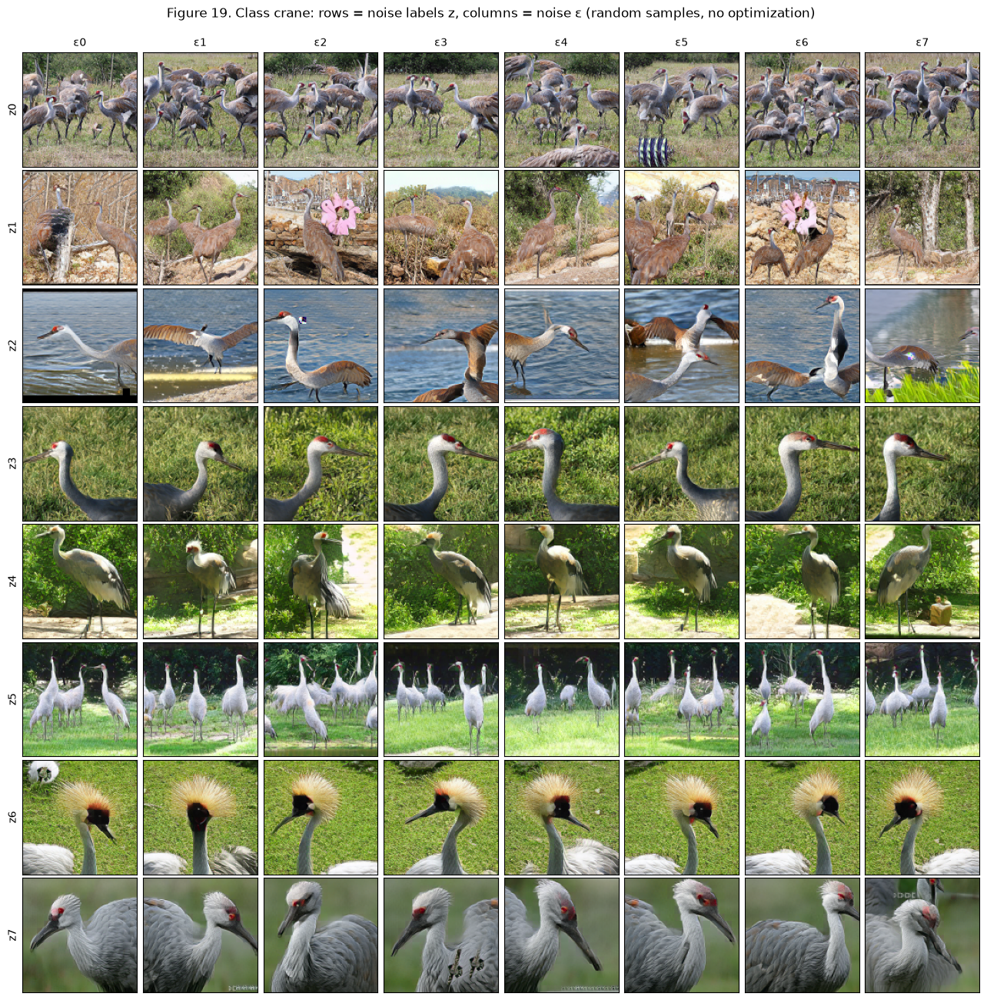

In [3]:
Z = R["z_vs_eps"]
DESC = ["colour mean/std", "radial power spectrum", "pooled AlexNet features", "16×16 thumbnail (layout)", "edge layout (32×32 gradient)"]
lines = ["| Descriptor | z share | ε share | interaction |", "|---|---:|---:|---:|"]
for d in DESC:
    sh = {p: np.mean([Z["anova_shares"][f"{c}|{d}"][p] for c in Z["classes"]]) for p in ("z", "ε", "interaction")}
    lines.append(f"| {d} | **{sh['z']:.2f}** | {sh['ε']:.2f} | {sh['interaction']:.2f} |")
display(Markdown("**Table 16. Share of variation due to z, ε and their interaction** (mean over 8 classes)\n\n" + "\n".join(lines)))
L = Z["locality"]
display(Markdown(
    "**Table 17. Locality of a change** (12 perturbations per class and kind)\n\n| Change | n | share of the change in the perturbed tile | "
    "in its 3×3 neighbourhood | spread (normalized entropy, 1 = uniform) | RMS change |\n|---|---:|---:|---:|---:|---:|\n"
    f"| one ε patch resampled | {L['eps_patch']['n']} | {L['eps_patch']['in_tile']:.3f} | {L['eps_patch']['in_3x3']:.3f} | "
    f"{L['eps_patch']['entropy']:.2f} | {L['eps_patch']['rms_change']:.3f} |\n"
    f"| one noise label z_i changed | {L['z_coord']['n']} | — | — | {L['z_coord']['entropy']:.2f} | {L['z_coord']['rms_change']:.3f} |\n"
    "| uniform spread (reference) | — | 0.004 | 0.035 | 1.00 | — |"))

fig, axes = plt.subplots(8, 8, figsize=(13, 13))
for k in range(8):
    for j in range(8):
        axes[k, j].imshow(_ex["grid_crane"][k, j])
        axes[k, j].set_xticks([])
        axes[k, j].set_yticks([])
    axes[k, 0].set_ylabel(f"z{k}", fontsize=10)
for j in range(8):
    axes[0, j].set_title(f"ε{j}", fontsize=10)
fig.suptitle("Figure 19. Class crane: rows = noise labels z, columns = noise ε (random samples, no optimization)", fontsize=12, y=0.995)
fig.subplots_adjust(left=0.03, right=0.99, bottom=0.01, top=0.95, wspace=0.03, hspace=0.03)
plt.show()

**Reading.** Each **row** (one $z$) is a different scene: a flock in grass, a single bird by water, a close-up
head. Each **column** (one $\varepsilon$) only shifts pose and positions within that scene. $z$ explains most of the
colour, spectrum and texture variation, and even 4× more of the layout than $\varepsilon$ does. Changing one of the
32 noise labels changes the whole image, about 8× more than resampling one $\varepsilon$ patch, whose effect stays
mostly nearby. So CSGM optimizes the weak half of the input and keeps a random draw of the strong half.

## 2. An image in place of $\varepsilon$ is ignored (3 development images)

If $\varepsilon$ were a "noisy image", feeding the photo itself should reproduce it. One forward pass with
$z$ fixed (CSGM's restart-0 draw) and

$$
\varepsilon_{\text{in}} = \alpha\, s + \sqrt{1 - \alpha^2}\; n, \qquad s = \text{per-channel standardized image}, \quad n \sim \mathcal N(0, I),
$$

for $\alpha \in \{0, 0.25, 0.5, 0.75, 1\}$ (the factor keeps unit variance), with $s$ from **bicubic($y$)** (available in
practice) or from the **HR photo** itself (an oracle), and the raw image as a last variant.

**Table 18. One forward pass with an image in ε: PSNR dB / LPIPS against HR** (no optimization, no BP)

| Image | input | α = 0 (noise) | 0.25 | 0.5 | 0.75 | 1 (image) | raw image | CSGM (5,000 steps) |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| 403 (crane) | bicubic(y) | 8.5 / 0.92 | 8.5 / 0.91 | 7.9 / 0.93 | 9.2 / 0.89 | 11.2 / 0.89 | 10.3 / 0.94 | 20.6 / 0.57 |
| 403 (crane) | HR (oracle) | 8.5 / 0.92 | 8.0 / 0.94 | 9.0 / 0.97 | 8.7 / 0.89 | 7.2 / 0.95 | 10.2 / 0.94 | 20.6 / 0.57 |
| 3939 (bonnet) | bicubic(y) | 7.2 / 0.79 | 7.1 / 0.79 | 7.2 / 0.79 | 7.4 / 0.78 | 7.3 / 0.84 | 7.5 / 0.83 | 22.3 / 0.39 |
| 3939 (bonnet) | HR (oracle) | 7.2 / 0.79 | 7.3 / 0.78 | 7.0 / 0.79 | 7.6 / 0.79 | 7.5 / 0.83 | 7.5 / 0.84 | 22.3 / 0.39 |
| 8405 (thimble) | bicubic(y) | 6.9 / 0.76 | 6.4 / 0.75 | 5.7 / 0.74 | 5.5 / 0.74 | 4.1 / 0.77 | 4.1 / 0.78 | 25.2 / 0.38 |
| 8405 (thimble) | HR (oracle) | 6.9 / 0.76 | 6.4 / 0.74 | 5.6 / 0.73 | 5.5 / 0.72 | 4.5 / 0.78 | 4.0 / 0.77 | 25.2 / 0.38 |

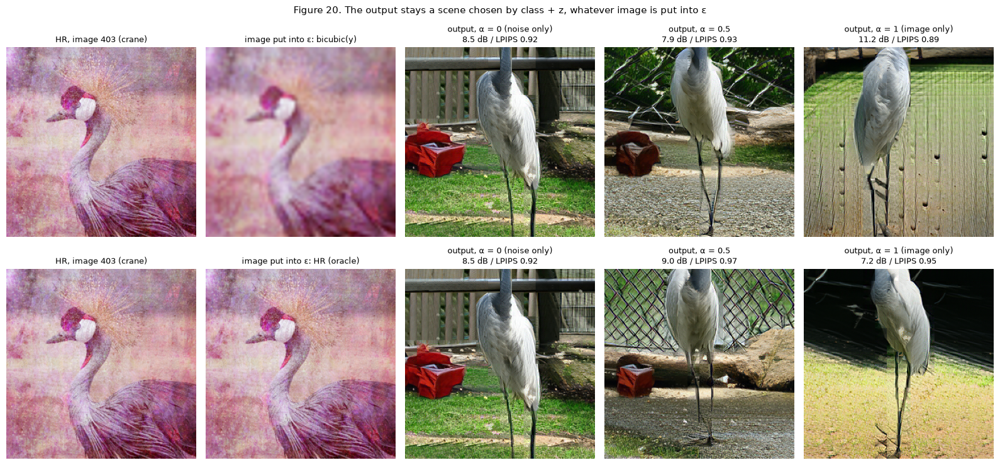

In [4]:
def image_in_eps(img, n, alpha):
    s = (img - img.mean(axis=(0, 1))) / img.std(axis=(0, 1))
    return alpha * s + np.sqrt(1 - alpha ** 2) * n
# Forward passes: scripts/dev/run_image_in_eps_dev.py.

G2 = R["image_in_eps"]
TAGS = [("a0", "α = 0 (noise)"), ("a0.25", "0.25"), ("a0.5", "0.5"), ("a0.75", "0.75"), ("a1", "1 (image)"), ("raw", "raw image")]
lines = ["| Image | input | " + " | ".join(t for _, t in TAGS) + " | CSGM (5,000 steps) |", "|---|---|" + "---:|" * (len(TAGS) + 1)]
for i in (403, 3939, 8405):
    for src in ("bicubic(y)", "HR (oracle)"):
        cs = G2[str(i)]["CSGM (5,000 steps)"]
        lines.append(f"| {i} ({NAME[i]}) | {src} | " + " | ".join(f"{G2[str(i)][f'{src}|{t}']['psnr']:.1f} / {G2[str(i)][f'{src}|{t}']['lpips']:.2f}"
                                                         for t, _ in TAGS) + f" | {cs['psnr']:.1f} / {cs['lpips']:.2f} |")
display(Markdown("**Table 18. One forward pass with an image in ε: PSNR dB / LPIPS against HR** (no optimization, no BP)\n\n" + "\n".join(lines)))

i = 403
fig, axes = plt.subplots(2, 5, figsize=(16, 7.8))
for row, src in enumerate(("bicubic(y)", "HR (oracle)")):
    axes[row, 0].imshow(show(EX(f"eps_img|{i}|HR")))
    axes[row, 0].set_title(f"HR, image {i} ({NAME[i]})", fontsize=9)
    axes[row, 1].imshow(show(EX(f"eps_img|{i}|{'bicubic' if row == 0 else 'HR'}")))
    axes[row, 1].set_title(f"image put into ε: {src}", fontsize=9)
    for k, (tag, title) in enumerate((("a0", "α = 0 (noise only)"), ("a0.5", "α = 0.5"), ("a1", "α = 1 (image only)")), start=2):
        m = G2[str(i)][f"{src}|{tag}"]
        axes[row, k].imshow(show(EX(f"eps_img|{i}|{src}|{tag}")))
        axes[row, k].set_title(f"output, {title}\n{m['psnr']:.1f} dB / LPIPS {m['lpips']:.2f}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Figure 20. The output stays a scene chosen by class + z, whatever image is put into ε", fontsize=11)
plt.tight_layout()
plt.show()

**Reading.** Whatever goes into $\varepsilon$, even the true photo, the output is a different scene chosen by the
class and $z$ (here a grey heron-like bird by a fence instead of a crowned crane on pink), at 4–11 dB. The image
structure in $\varepsilon$ is not turned into content. This is why CSGM has to push $\varepsilon$ so far
off-distribution to reproduce a photo (Section 3): it forces the weak input to do the work of the strong one.

## 3. Keeping $\varepsilon$ Gaussian doesn't help (4 development images)

For $\varepsilon \sim \mathcal N(0, I)$, each $16\times16\times3$ patch $p$ (one token) has $\|p\|/\sqrt{768} \approx 1$
with standard deviation $1/\sqrt{2 \cdot 768} \approx 0.026$: a thin shell. Does CSGM leave it, and does forcing it back
help? Two projections applied after every Adam step (as in PULSE):

$$
\textbf{global:}\ \ \varepsilon \leftarrow \varepsilon\, \frac{\sqrt{d}}{\|\varepsilon\|}\ \ (d = 196{,}608) ,
\qquad
\textbf{per patch:}\ \ p \leftarrow p\, \frac{\sqrt{768}}{\|p\|}\ \ \text{for every patch } p .
$$

Everything else is CSGM as in notebook 1 (same starts, 5,000 steps, best of 2 restarts by LR loss).

**Table 19. ε statistics: start vs after CSGM** (mean over 4 images; per-patch norm / √768)

| ε | RMS | patch norm, mean | patch norm, std | patch norm, max | ‖ε − ε₀‖ / ‖ε₀‖ |
|---|---:|---:|---:|---:|---:|
| start ε₀ (Gaussian) | 1.00 | 1.00 | 0.025 | 1.07 | — |
| after CSGM, none | 1.70 | 1.65 | 0.408 | 3.40 | 1.38 |
| after CSGM, global sphere | 1.00 | 0.94 | 0.317 | 2.21 | 1.13 |
| after CSGM, per-patch sphere | 1.00 | 1.00 | 0.000 | 1.00 | 1.07 |

**Table 20a. Sphere projection, CSGM output** (4 images; Δ vs no projection)

| Projection | PSNR (dB) ↑ | LPIPS ↓ | LR loss | Δ PSNR | better | Δ LPIPS | better |
|---|---:|---:|---:|---:|---:|---:|---:|
| none | 21.06 | 0.406 | 50.5 | +0.00 | 0/4 | +0.000 | 0/4 |
| global sphere | 20.74 | 0.480 | 67.7 | -0.32 | 1/4 | +0.074 | 0/4 |
| per-patch sphere | 20.73 | 0.477 | 85.1 | -0.32 | 0/4 | +0.071 | 0/4 |

**Table 20b. Sphere projection, after back-projection** (4 images; Δ vs no projection)

| Projection | PSNR (dB) ↑ | LPIPS ↓ | LR loss | Δ PSNR | better | Δ LPIPS | better |
|---|---:|---:|---:|---:|---:|---:|---:|
| none | 21.86 | 0.328 | 0.0 | +0.00 | 0/4 | +0.000 | 0/4 |
| global sphere | 21.72 | 0.388 | 0.0 | -0.14 | 2/4 | +0.060 | 0/4 |
| per-patch sphere | 21.99 | 0.373 | 0.0 | +0.13 | 3/4 | +0.045 | 1/4 |

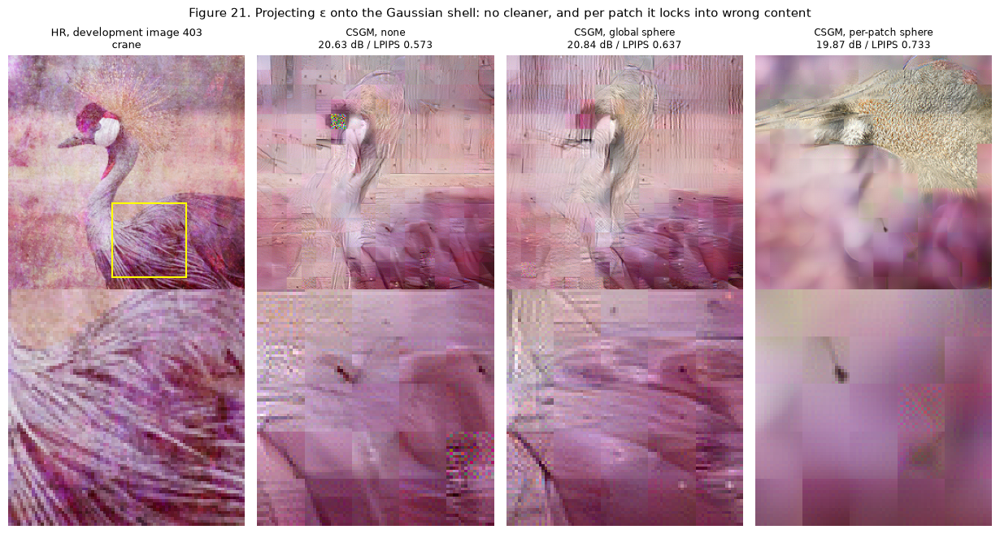

In [5]:
def project_global(eps):
    return eps * np.sqrt(eps.size) / np.linalg.norm(eps)


def project_patch(eps):
    b = eps.reshape(1, 16, 16, 16, 16, 3)  # (batch, grid row, pixel row, grid col, pixel col, channel)
    return (b * np.sqrt(768.0) / np.sqrt(np.sum(b ** 2, axis=(2, 4, 5), keepdims=True))).reshape(eps.shape)


S = R["sphere"]
st = lambda v, k: np.mean([S[str(i)][v]["eps"][k] for i in DEV4])
display(Markdown(
    "**Table 19. ε statistics: start vs after CSGM** (mean over 4 images; per-patch norm / √768)\n\n"
    "| ε | RMS | patch norm, mean | patch norm, std | patch norm, max | ‖ε − ε₀‖ / ‖ε₀‖ |\n|---|---:|---:|---:|---:|---:|\n"
    f"| start ε₀ (Gaussian) | {np.mean([S[str(i)]['none']['init_eps']['rms'] for i in DEV4]):.2f} | "
    f"{np.mean([S[str(i)]['none']['init_eps']['patch_norm_mean'] for i in DEV4]):.2f} | "
    f"{np.mean([S[str(i)]['none']['init_eps']['patch_norm_std'] for i in DEV4]):.3f} | "
    f"{np.mean([S[str(i)]['none']['init_eps']['patch_norm_max'] for i in DEV4]):.2f} | — |\n"
    + "\n".join(f"| after CSGM, {v} | {st(v, 'rms'):.2f} | {st(v, 'patch_norm_mean'):.2f} | {st(v, 'patch_norm_std'):.3f} | "
                f"{st(v, 'patch_norm_max'):.2f} | {st(v, 'rel_change'):.2f} |" for v in ("none", "global sphere", "per-patch sphere"))))

VAR = ["none", "global sphere", "per-patch sphere"]
for kind, title in (("raw", "CSGM output"), ("bp", "after back-projection")):
    ref_p = np.array([S[str(i)]["none"][kind]["psnr"] for i in DEV4])
    ref_l = np.array([S[str(i)]["none"][kind]["lpips"] for i in DEV4])
    lines = ["| Projection | PSNR (dB) ↑ | LPIPS ↓ | LR loss | Δ PSNR | better | Δ LPIPS | better |", "|---|---:|---:|---:|---:|---:|---:|---:|"]
    for v in VAR:
        p = np.array([S[str(i)][v][kind]["psnr"] for i in DEV4])
        l = np.array([S[str(i)][v][kind]["lpips"] for i in DEV4])
        lr = np.mean([S[str(i)][v][kind]["lr_loss"] for i in DEV4])
        lines.append(f"| {v} | {p.mean():.2f} | {l.mean():.3f} | {lr:.1f} | {np.mean(p - ref_p):+.2f} | {int(np.sum(p > ref_p + 1e-9))}/4 | "
                     f"{np.mean(l - ref_l):+.3f} | {int(np.sum(l < ref_l - 1e-9))}/4 |")
    display(Markdown(f"**Table 20{'a' if kind == 'raw' else 'b'}. Sphere projection, {title}** (4 images; Δ vs no projection)\n\n" + "\n".join(lines)))

i = 403
side_by_side(EX(f"sphere|{i}|HR"), f"HR, development image {i}\n{NAME[i]}",
             [(f"CSGM, {v}", EX(f"sphere|{i}|{v}"), S[str(i)][v]["raw"]) for v in VAR],
             "Figure 21. Projecting ε onto the Gaussian shell: no cleaner, and per patch it locks into wrong content")

**Reading.** CSGM inflates the per-patch norms by 1.4–1.8× on average and their spread by more than 10×. The
projections enforce the shell exactly, but cost measurement fit and make LPIPS worse on every image (PSNR −0.3 dB);
after back-projection the per-patch variant gains 0.1 dB but stays worse on LPIPS. Off-distribution $\varepsilon$ is
a *symptom* (the weak input is being forced to change the scene, Sections 1–2), not the cause of the artifacts. This also
answers the suggestion to regularize $\varepsilon$ towards a Gaussian, for the noiseless case.

## 4. Choosing $z$ by measurement fit: noise-label search (4 development images)

$z$ is discrete, so gradient methods can't optimize it (relaxed versions are listed in Section 7). Instead, search:

1. **Candidates:** the 2 CSGM starts $\varepsilon_r$ × 8 noise-label draws $z_j$ ($z_0$ = CSGM's own) = 16 candidates.
2. **Screen:** 500 CSGM steps each; keep the 2 with the lowest LR loss $\|y - A x\|^2$.
3. **Finish:** 5,000 steps for the 2 finalists; return the one with the lowest final LR loss. HR is never used.

Cost: $16 \times 500 + 2 \times 5{,}000 = 18{,}000$ steps per image, 1.8× CSGM's $10{,}000$.

**Table 21a. Noise-label search, CSGM output** (4 images)

| Method | PSNR (dB) ↑ | LPIPS ↓ | LR loss | Δ PSNR | better | Δ LPIPS | better |
|---|---:|---:|---:|---:|---:|---:|---:|
| CSGM (best of 2 restarts) | 21.06 | 0.406 | 50.5 | +0.00 | 0/4 | +0.000 | 0/4 |
| CSGM + noise-label search | 21.61 | 0.365 | 30.0 | +0.55 | 3/4 | -0.040 | 2/4 |

**Table 21b. Noise-label search, after back-projection** (4 images)

| Method | PSNR (dB) ↑ | LPIPS ↓ | LR loss | Δ PSNR | better | Δ LPIPS | better |
|---|---:|---:|---:|---:|---:|---:|---:|
| CSGM (best of 2 restarts) | 21.86 | 0.328 | 0.0 | +0.00 | 0/4 | +0.000 | 0/4 |
| CSGM + noise-label search | 22.10 | 0.314 | 0.0 | +0.24 | 2/4 | -0.013 | 1/4 |

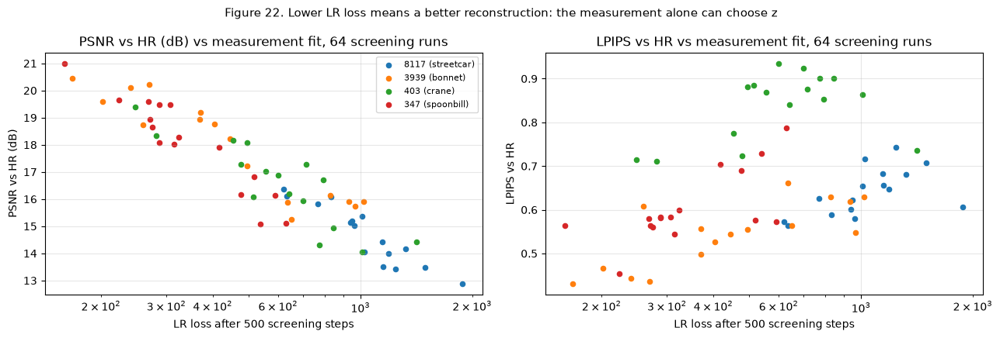

**Table 22. Is LR loss a good selection signal?** (HR used for this analysis only)

| Image | chosen (restart, code) | Spearman(LR loss, PSNR) | Spearman(LR loss, LPIPS) | HR-best candidate's rank by LR loss |
|---|---|---:|---:|---:|
| 8117 (streetcar) | r1_nl0 | -0.93 | +0.68 | 1 of 16 |
| 3939 (bonnet) | r1_nl2 | -0.88 | +0.72 | 1 of 16 |
| 403 (crane) | r0_nl5 | -0.85 | +0.39 | 1 of 16 |
| 347 (spoonbill) | r1_nl3 | -0.94 | +0.63 | 1 of 16 |

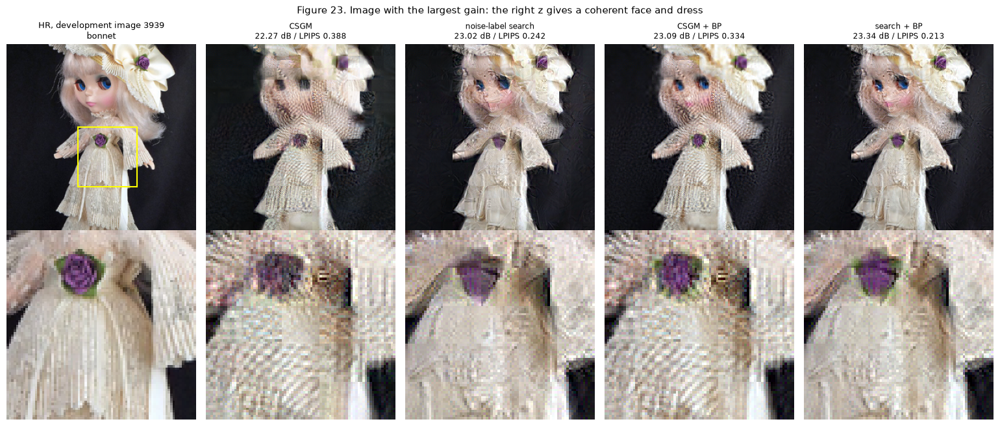

In [6]:
def noise_label_search(run_csgm, starts, codes, screen_steps=500, final_steps=5_000, finalists=2):
    """run_csgm(eps0, z, steps) -> (x, lr_loss). Every choice uses the LR loss only."""
    screened = sorted(((run_csgm(e, z, screen_steps)[1], r, j) for r, e in enumerate(starts) for j, z in enumerate(codes)))
    finals = [(run_csgm(starts[r], codes[j], final_steps), r, j) for _, r, j in screened[:finalists]]
    (x, loss), r, j = min(finals, key=lambda f: f[0][1])
    return x
# The runs: scripts/dev/run_noise_label_search_dev.py (cache noise_label_search_dev_v1/).

N = R["noise_label_search"]
for kind, title in (("raw", "CSGM output"), ("bp", "after back-projection")):
    rp = np.array([N[str(i)]["baseline"][kind]["psnr"] for i in DEV4])
    rl = np.array([N[str(i)]["baseline"][kind]["lpips"] for i in DEV4])
    lines = ["| Method | PSNR (dB) ↑ | LPIPS ↓ | LR loss | Δ PSNR | better | Δ LPIPS | better |", "|---|---:|---:|---:|---:|---:|---:|---:|"]
    for k, label in (("baseline", "CSGM (best of 2 restarts)"), ("search", "CSGM + noise-label search")):
        p = np.array([N[str(i)][k][kind]["psnr"] for i in DEV4])
        l = np.array([N[str(i)][k][kind]["lpips"] for i in DEV4])
        lines.append(f"| {label} | {p.mean():.2f} | {l.mean():.3f} | {np.mean([N[str(i)][k][kind]['lr_loss'] for i in DEV4]):.1f} | "
                     f"{np.mean(p - rp):+.2f} | {int(np.sum(p > rp + 1e-9))}/4 | {np.mean(l - rl):+.3f} | {int(np.sum(l < rl - 1e-9))}/4 |")
    display(Markdown(f"**Table 21{'a' if kind == 'raw' else 'b'}. Noise-label search, {title}** (4 images)\n\n" + "\n".join(lines)))

lines = ["| Image | chosen (restart, code) | Spearman(LR loss, PSNR) | Spearman(LR loss, LPIPS) | HR-best candidate's rank by LR loss |",
         "|---|---|---:|---:|---:|"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for c, i in enumerate(DEV4):
    sc = N[str(i)]["screen"]
    loss, p, l = (np.array([s[k] for s in sc]) for k in ("lr_loss", "psnr", "lpips"))
    best_hr = int(np.argmax(p))
    rank = int(np.sum(loss < loss[best_hr])) + 1
    lines.append(f"| {i} ({NAME[i]}) | {N[str(i)]['best']} | {spearmanr(loss, p)[0]:+.2f} | {spearmanr(loss, l)[0]:+.2f} | {rank} of 16 |")
    axes[0].scatter(loss, p, s=20, color=f"C{c}", label=f"{i} ({NAME[i]})")
    axes[1].scatter(loss, l, s=20, color=f"C{c}")
for ax, t in zip(axes, ("PSNR vs HR (dB)", "LPIPS vs HR")):
    ax.set(xscale="log", xlabel="LR loss after 500 screening steps", ylabel=t, title=f"{t} vs measurement fit, 64 screening runs")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle("Figure 22. Lower LR loss means a better reconstruction: the measurement alone can choose z", fontsize=11)
plt.tight_layout()
plt.show()
display(Markdown("**Table 22. Is LR loss a good selection signal?** (HR used for this analysis only)\n\n" + "\n".join(lines)))

i = 3939
side_by_side(EX(f"nls|{i}|HR"), f"HR, development image {i}\n{NAME[i]}",
             [("CSGM", EX(f"nls|{i}|baseline"), N[str(i)]["baseline"]["raw"]), ("noise-label search", EX(f"nls|{i}|search"), N[str(i)]["search"]["raw"]),
              ("CSGM + BP", EX(f"nls|{i}|baseline + BP"), N[str(i)]["baseline"]["bp"]),
              ("search + BP", EX(f"nls|{i}|search + BP"), N[str(i)]["search"]["bp"])],
             "Figure 23. Image with the largest gain: the right z gives a coherent face and dress")

**Reading.** Searching $z$ lowers the LR loss a lot (50 → 30) and improves the raw output (+0.55 dB, LPIPS −0.040);
after back-projection the gain shrinks (+0.24 dB, −0.013) and is mixed per image. The more reliable finding is the
**selection signal**: across 64 screening runs, lower LR loss goes with higher PSNR (Spearman −0.85 to −0.94), and on
every image the HR-best candidate was also the best by LR loss. The same principle drives the LR-loss weighting of
the ensemble in notebook 3.

## 5. Averaging rescues IADrift: the averaging matters, not the adaptation (6 development images)

Notebook 3 averaged 5 CSGM runs (the development version, on these 6 images, is what motivated that test run). Here
we also run IADrift from **each** of the 5 CSGM members and average the adapted outputs:

$$
\hat x_{\text{IADrift ens}} = \mathrm{BP}\Big(\sum_{k=1}^{5} w_k\, \mathrm{IADrift}_{T}(x_k)\Big), \qquad T \in \{100, 1000\},
$$

with uniform weights (Ens-U) or the LR-loss weights of the CSGM members (Ens-W).

**Table 23. Ensembles of CSGM and of IADrift runs** (6 development images, all + BP)

| Method | PSNR (dB) ↑ | LPIPS ↓ | SNR very high | Δ PSNR vs CSGM + BP | better | Δ LPIPS | better |
|---|---:|---:|---:|---:|---:|---:|---:|
| CSGM + BP | 22.45 | 0.303 | -4.7 | +0.00 | 0/6 | +0.000 | 0/6 |
| CSGM ensemble Ens-U + BP | 24.81 | 0.302 | -2.0 | +2.36 | 6/6 | -0.001 | 4/6 |
| CSGM ensemble Ens-W + BP | 24.04 | 0.273 | -2.8 | +1.60 | 6/6 | -0.029 | 5/6 |
| IADrift @100, single + BP | 22.14 | 0.304 | -5.1 | -0.31 | 1/6 | +0.002 | 3/6 |
| IADrift @100 ensemble Ens-U + BP | 24.71 | 0.293 | -2.3 | +2.27 | 6/6 | -0.010 | 4/6 |
| IADrift @100 ensemble Ens-W + BP | 23.82 | 0.273 | -3.1 | +1.38 | 6/6 | -0.030 | 5/6 |
| IADrift @1000, single + BP | 19.05 | 0.421 | -9.2 | -3.40 | 0/6 | +0.118 | 0/6 |
| IADrift @1000 ensemble Ens-U + BP | 23.00 | 0.318 | -4.9 | +0.55 | 4/6 | +0.015 | 4/6 |
| IADrift @1000 ensemble Ens-W + BP | 21.65 | 0.345 | -6.3 | -0.80 | 0/6 | +0.042 | 2/6 |

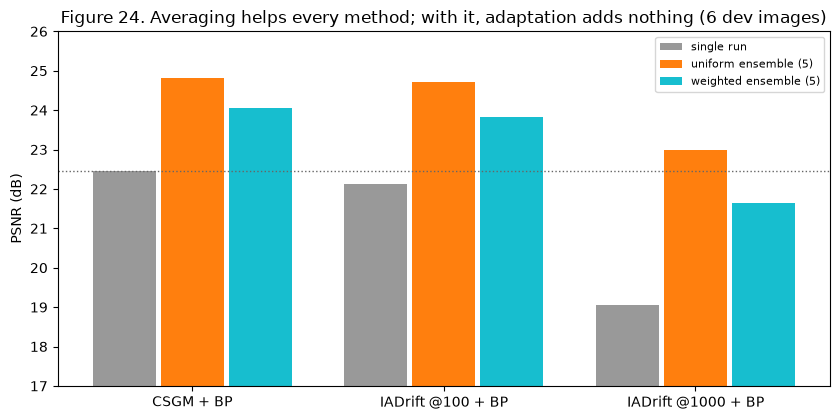

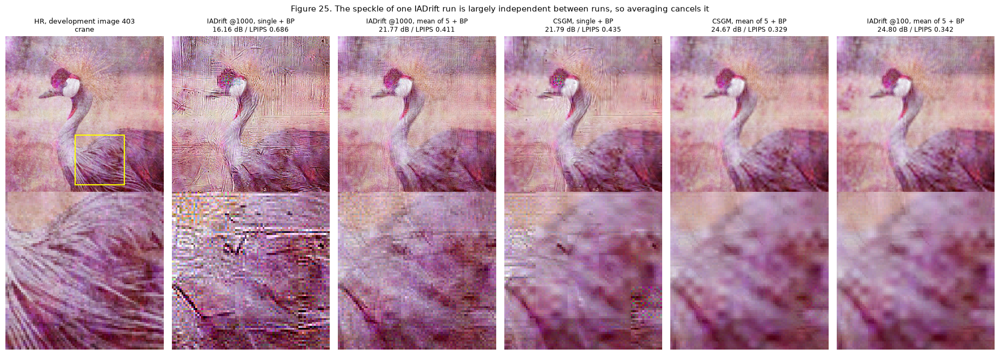

In [7]:
E = R["ensembles"]
ROWS = [("CSGM + BP", "CSGM"), ("CSGM ensemble Ens-U + BP", "CSGM Ens-U"), ("CSGM ensemble Ens-W + BP", "CSGM Ens-W"),
        ("IADrift @100, single + BP", "IADrift @100"), ("IADrift @100 ensemble Ens-U + BP", "IADrift @100 Ens-U"),
        ("IADrift @100 ensemble Ens-W + BP", "IADrift @100 Ens-W"),
        ("IADrift @1000, single + BP", "IADrift @1000"), ("IADrift @1000 ensemble Ens-U + BP", "IADrift @1000 Ens-U"),
        ("IADrift @1000 ensemble Ens-W + BP", "IADrift @1000 Ens-W")]
rp, rl = (np.array([E[str(i)]["CSGM"][k] for i in DEV6]) for k in ("psnr", "lpips"))
lines = ["| Method | PSNR (dB) ↑ | LPIPS ↓ | SNR very high | Δ PSNR vs CSGM + BP | better | Δ LPIPS | better |", "|---|---:|---:|---:|---:|---:|---:|---:|"]
for name, k in ROWS:
    p, l = (np.array([E[str(i)][k][m] for i in DEV6]) for m in ("psnr", "lpips"))
    vh = np.mean([E[str(i)][k]["band_snr_db"]["very high"] for i in DEV6])
    lines.append(f"| {name} | {p.mean():.2f} | {l.mean():.3f} | {vh:+.1f} | {np.mean(p - rp):+.2f} | {int(np.sum(p > rp + 1e-9))}/6 | "
                 f"{np.mean(l - rl):+.3f} | {int(np.sum(l < rl - 1e-9))}/6 |")
display(Markdown("**Table 23. Ensembles of CSGM and of IADrift runs** (6 development images, all + BP)\n\n" + "\n".join(lines)))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
groups, xs = ["CSGM", "IADrift @100", "IADrift @1000"], np.arange(3)
for off, (suffix, label, color) in zip((-0.27, 0, 0.27), (("", "single run", "0.6"), (" Ens-U", "uniform ensemble (5)", "C1"), (" Ens-W", "weighted ensemble (5)", "C9"))):
    vals = [np.mean([E[str(i)][g + suffix]["psnr"] for i in DEV6]) for g in groups]
    ax.bar(xs + off, vals, 0.25, color=color, label=label)
ax.set(xticks=xs, xticklabels=[g + " + BP" for g in groups], ylabel="PSNR (dB)", ylim=(17, 26),
       title="Figure 24. Averaging helps every method; with it, adaptation adds nothing (6 dev images)")
ax.axhline(np.mean([E[str(i)]["CSGM"]["psnr"] for i in DEV6]), color="0.4", ls=":", lw=1)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

i = 403
side_by_side(EX(f"ens|{i}|HR"), f"HR, development image {i}\n{NAME[i]}",
             [("IADrift @1000, single + BP", EX(f"ens|{i}|IADrift @1000 + BP"), E[str(i)]["IADrift @1000"]),
              ("IADrift @1000, mean of 5 + BP", EX(f"ens|{i}|IADrift @1000 Ens-U + BP"), E[str(i)]["IADrift @1000 Ens-U"]),
              ("CSGM, single + BP", EX(f"ens|{i}|CSGM + BP"), E[str(i)]["CSGM"]),
              ("CSGM, mean of 5 + BP", EX(f"ens|{i}|CSGM Ens-U + BP"), E[str(i)]["CSGM Ens-U"]),
              ("IADrift @100, mean of 5 + BP", EX(f"ens|{i}|IADrift @100 Ens-U + BP"), E[str(i)]["IADrift @100 Ens-U"])],
             "Figure 25. The speckle of one IADrift run is largely independent between runs, so averaging cancels it")

**Reading.** A single IADrift @1000 run is far worse than CSGM (−3.4 dB); averaging 5 of them gains about 4 dB
and lifts it above single CSGM, because the high-frequency noise each run invents is largely independent and
cancels (very-high band −9.2 → −4.9 dB). At 100 steps, IADrift ensembles are within about 0.2 dB and 0.01 LPIPS of the
CSGM ensembles built from the same members. **Once reconstructions are averaged, adapting the weights adds nothing:**
averaging does what adaptation was hoped to do.

## 6. Suppressing the high-frequency noise directly (one development image: an illustration)

Two penalties that target the band above $f_{\text{LR}}$ selectively (untuned, image 403 only):

**A. Colour penalty in CSGM.** In photos, fine detail is almost all brightness; colour varies slowly. The colour
"confetti" tiles are high-frequency chroma, so

$$
\mathcal L_A(\varepsilon) = \|y - A G(\varepsilon)\|^2 + \lambda_A \big\|\mathrm{HP}\big(\mathrm{chroma}(G(\varepsilon))\big)\big\|^2 , \qquad \lambda_A = 0.1,
$$

with chroma = the Cb, Cr channels of YCbCr and HP = keep radial frequencies $\ge f_{\text{LR}}$.

**B. Frequency anchor in IADrift.** Let the weights adapt, but penalize changes of the image's high band relative to
the CSGM start $x_0$:

$$
\mathcal L_B(\theta, \varepsilon) = \|y - A G_\theta(\varepsilon)\|^2 + \lambda_B \big\|\mathrm{HP}\big(G_\theta(\varepsilon) - x_0\big)\big\|^2 , \qquad \lambda_B = 0.02 .
$$

**Table 24. High-frequency penalties, image 403 (crane)** (single run = restart 0; ensemble as in notebook 3)

| Method (all + BP) | single run: PSNR / LPIPS | colour energy above f_LR | blockiness | weighted ensemble of 5: PSNR / LPIPS |
|---|---:|---:|---:|---:|
| bicubic + BP | 25.55 / 0.593 | 9 | 0.99 | — |
| CSGM | 21.79 / 0.435 | 646 | 1.18 | 24.29 / 0.361 |
| CSGM + A (colour penalty) | 23.86 / 0.407 | 62 | 1.36 | 24.99 / 0.361 |
| IADrift @1000 | 16.16 / 0.686 | 2409 | 0.83 | 20.40 / 0.515 |
| IADrift + B (anchor) @1000 | 21.71 / 0.430 | 653 | 1.21 | 24.24 / 0.351 |
| CSGM + A → IADrift + B @1000 | 23.71 / 0.398 | 71 | 1.39 | 24.93 / 0.348 |

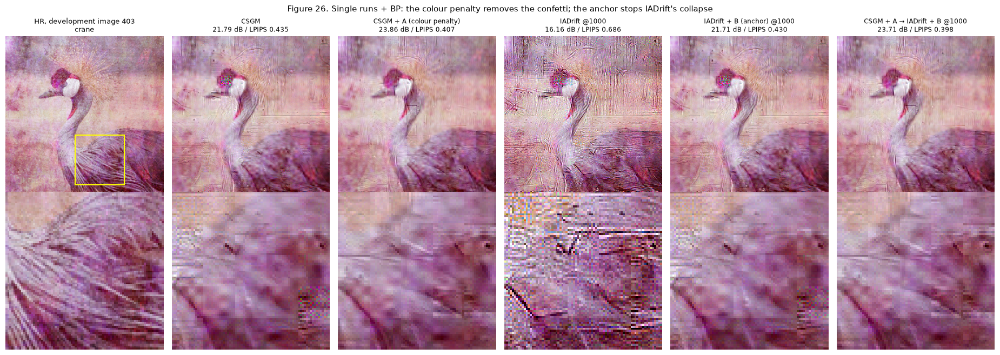

In [8]:
def chroma(x):
    """Cb, Cr of YCbCr for an RGB image in [-1, 1]."""
    return np.stack([-0.1687 * x[..., 0] - 0.3313 * x[..., 1] + 0.5 * x[..., 2],
                     0.5 * x[..., 0] - 0.4187 * x[..., 1] - 0.0813 * x[..., 2]], -1)


def high_pass(x, f_lr=0.125):
    f = np.fft.fftfreq(x.shape[0])
    mask = (np.sqrt(f[:, None] ** 2 + f[None, :] ** 2) >= f_lr)[..., None]
    return np.real(np.fft.ifft2(np.fft.fft2(x, axes=(0, 1)) * mask, axes=(0, 1)))


def loss_A(x, y, A, lam=0.1):
    return np.sum((A(x) - y) ** 2) + lam * np.sum(high_pass(chroma(x)) ** 2)


def loss_B(x, y, A, x0, lam=0.02):
    return np.sum((A(x) - y) ** 2) + lam * np.sum(high_pass(x - x0) ** 2)
# The runs (JAX versions with gradients): scripts/dev/run_hf_constraints_dev.py.

H = R["hf_constraints"]
V6 = [("bicubic + BP", "bicubic + BP"), ("CSGM", "CSGM"), ("CSGM + A (colour penalty)", "CSGM + A"),
      ("IADrift @1000", "IADrift @1000"), ("IADrift + B (anchor) @1000", "IADrift + B @1000"),
      ("CSGM + A → IADrift + B @1000", "A → IADrift + B @1000")]
lines = ["| Method (all + BP) | single run: PSNR / LPIPS | colour energy above f_LR | blockiness | weighted ensemble of 5: PSNR / LPIPS |",
         "|---|---:|---:|---:|---:|"]
for name, k in V6:
    s = H[f"{k}|single"]
    w = H.get(f"{k}|weighted")
    lines.append(f"| {name} | {s['psnr']:.2f} / {s['lpips']:.3f} | {s['chroma_hf']:.0f} | {s['blockiness']:.2f} | "
                 + (f"{w['psnr']:.2f} / {w['lpips']:.3f}" if w else "—") + " |")
display(Markdown("**Table 24. High-frequency penalties, image 403 (crane)** (single run = restart 0; ensemble as in notebook 3)\n\n" + "\n".join(lines)))

side_by_side(EX("hfc|HR"), "HR, development image 403\ncrane",
             [(name, EX(f"hfc|{k}|single"), H[f"{k}|single"]) for name, k in V6[1:]],
             "Figure 26. Single runs + BP: the colour penalty removes the confetti; the anchor stops IADrift's collapse")

**Reading (one image, untuned).** The colour penalty cuts the high-frequency colour energy by 90% and gains 2 dB
with better LPIPS. The anchor does exactly what it is meant to: IADrift @1000 no longer collapses (16.2 → 21.7 dB)
because its high band can't drift. Together they give the best single run here (23.7 dB / 0.398 vs 21.8 / 0.435 for
CSGM). In the ensemble the gains are smaller, because averaging already removes most of the same noise. A side
effect: removing colour noise exposes the brightness tile seams (blockiness up). Worth testing on more images; not
evidence on its own.

## 7. Also tried (development; one line each)

| Experiment | What | $n$ | Result |
|---|---|---:|---|
| Frequency fusion | bicubic outside the mid band, IADrift inside | 4 | The prior-free control (bicubic + BP + fusion) wins on 4/4: the gain is back-projection, not the prior |
| Soft $z$ optimization | relax $z$ to mixtures of embeddings, optimize with $\varepsilon$ | 4 | Works only as a soft mixture (rounding destroys it, 21.7 → 13.8 dB); no gain after BP |
| Discrete $z$ swaps | swap single noise labels during CSGM | 4 + 2 | Late swaps never improve the fit (0 of 2,016); early swaps mixed and not robust on 2 fresh images |
| Better $z$ start + IADrift @100 | noise-label search or swaps, then IADrift | 6 | Gains don't stack; best remains search + BP |
| Texture knob, restart averaging, seam penalty, 4-shift ensemble | post-processing and penalties | 1 | Each beats CSGM + BP on that image; combinations over-smooth |

## 8. Summary

- **The drift generator's latent is dominated by the discrete noise labels $z$** (Sections 1–2); $\varepsilon$ is a weak, local
  input that CSGM must push off-distribution (Section 3). Regularizing $\varepsilon$ towards a Gaussian doesn't help (Section 3).
- **Choosing $z$ by measurement fit** helps a little, and LR loss is a reliable selection signal (Section 4).
- **Averaging is the ingredient that matters** (Section 5): it rescues even badly over-adapted IADrift runs, and makes
  moderate adaptation redundant.
- **Targeted high-frequency penalties** are a promising direction (Section 6), shown on one image only.

These all point the same way as notebooks 1–3: the hard part of SR with this prior is the content above the LR limit,
and the useful tools are the ones that remove wrong content there, not the ones that add freedom.